# Python机器学习基础教程 ch05：模型评估与改进

对应笔记 [ch05.md](../ch05.md)。本 notebook 是**分节跟随代码**：小节结构与笔记一致，完整讲解、原书插图与“坑与陷阱”请看笔记页面。

运行环境：`machinelearn`（Python 3.10 / scikit-learn 1.7 / pandas 2.3 / mglearn，mglearn 已打 boston 本地数据补丁）。原书 0.19 时代 API 的适配处在代码注释中以 **版本适配** 标出，与笔记中的“版本差异” admonition 一一对应。

In [1]:
# ===== 公共设置（notebook 版新增；原书在 Jupyter 全局环境中运行）=====
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mglearn

# 兜底：nbclient/nbconvert 实跑时 inline 后端的 flush_figures 钩子未注册，
# 图会留在内存不进输出——这里手动补一个“每个 cell 结束时把打开的图显示出来”
import IPython
_ip = IPython.get_ipython()
if _ip is not None:
    def _flush_figs():
        if plt.get_fignums():
            plt.show()
    _ip.events.register("post_execute", _flush_figs)

print("sklearn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

sklearn 1.7.0 | pandas 2.3.3 | numpy 2.2.6


**本章解决**：怎么科学地给监督模型"打分"，并把这个分数用对地方。前三章我们一直用 train_test_split + score 这把"单次划分的尺子"，本章先把它换成更稳的**交叉验证**，再解决"调参把测试集用坏"的问题——网格搜索、验证集、嵌套交叉验证；最后补齐指标本身：精度之外还有 F1、准确率-召回率曲线、ROC/AUC、多分类平均策略与回归 \(R^2\)。这一章的工具和第 2、3 章的算法一起构成机器学习从业者的日常装备；下一章的 Pipeline 会把"预处理 + 模型"串成链，让网格搜索与交叉验证能覆盖整条流水线。

In [2]:
# ===== 书第 5 章开篇：复习 train_test_split + score 的老流程 =====
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 创建一个模拟数据集
X, y = make_blobs(random_state=0)
# 将数据和标签划分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
# 将模型实例化，并用它来拟合训练集
logreg = LogisticRegression().fit(X_train, y_train)
# 在测试集上评估该模型
print("Test set score: {:.2f}".format(logreg.score(X_test, y_test)))

Test set score: 0.88


## 5.1 交叉验证

交叉验证（**cross-validation**）是一种评估泛化性能的统计学方法，它比单次划分训练集和测试集的方法**更加稳定、全面**。在交叉验证中，数据被多次划分，并且需要训练多个模型。

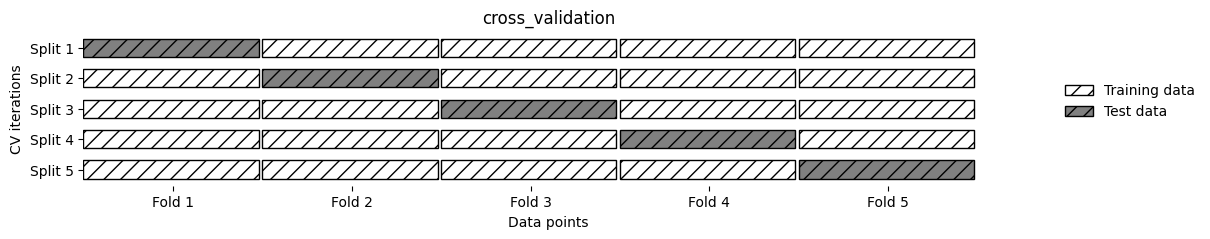

In [3]:
# ===== 书 5.1 节：画出 5 折交叉验证的划分方式 =====
mglearn.plots.plot_cross_validation()

### 5.1.1 scikit-learn 中的交叉验证

scikit-learn 用 model_selection 模块中的 **cross_val_score 函数**实现交叉验证。它的参数是：想评估的模型、训练数据与真实标签。我们在 iris 数据集上评估 LogisticRegression：

In [4]:
# ===== 书 5.1.1 节：cross_val_score 默认划分 =====
from sklearn.model_selection import cross_val_score
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

iris = load_iris()
logreg = LogisticRegression()

scores = cross_val_score(logreg, iris.data, iris.target)
print("Cross-validation scores: {}".format(scores))

Cross-validation scores: [0.96666667 1.         0.93333333 0.96666667 1.        ]


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [5]:
# ===== 书 5.1.1 节：cv=5 =====
scores = cross_val_score(logreg, iris.data, iris.target, cv=5)
print("Cross-validation scores: {}".format(scores))

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Cross-validation scores: [0.96666667 1.         0.93333333 0.96666667 1.        ]


In [6]:
# ===== 书 5.1.1 节：平均交叉验证精度 =====
print("Average cross-validation score: {:.2f}".format(scores.mean()))

Average cross-validation score: 0.97


### 5.1.2 交叉验证的优点

用交叉验证而不是单次划分训练集和测试集，有三大优点：

### 5.1.3 分层k折交叉验证和其他策略

把数据集划分为 \(k\) 折时，"从数据的前 \(k\) 分之一开始切"（上一节的默认做法）并不总是一个好主意。看 iris 数据集：

In [7]:
# ===== 书 5.1.3 节：iris 的标签是按顺序排列的 =====
from sklearn.datasets import load_iris
iris = load_iris()
print("Iris labels:\n{}".format(iris.target))

Iris labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


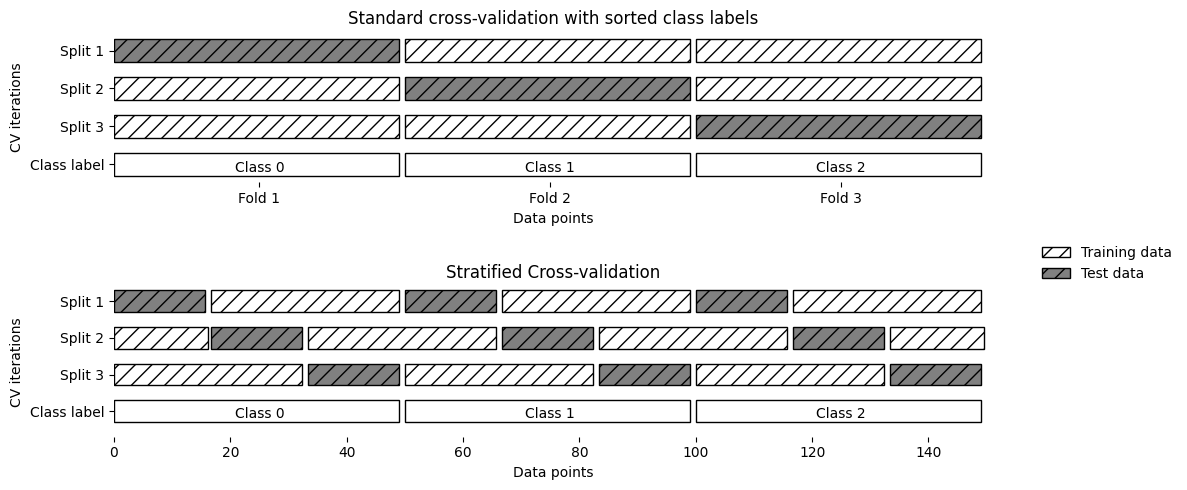

In [8]:
# ===== 书 5.1.3 节：对比标准 k 折与分层 k 折 =====
mglearn.plots.plot_stratified_cross_validation()

In [9]:
# ===== 书 5.1.3 节第 1 小节：KFold 分离器 =====
from sklearn.model_selection import KFold
kfold = KFold(n_splits=5)

In [10]:
# ===== 书 5.1.3 节第 1 小节：用标准 5 折评估 iris =====
print("Cross-validation scores:\n{}".format(
      cross_val_score(logreg, iris.data, iris.target, cv=kfold)))

Cross-validation scores:
[1.         1.         0.86666667 0.93333333 0.83333333]


In [11]:
# ===== 书 5.1.3 节第 1 小节：不分层的 3 折，精度为 0 =====
kfold = KFold(n_splits=3)
print("Cross-validation scores:\n{}".format(
    cross_val_score(logreg, iris.data, iris.target, cv=kfold)))

Cross-validation scores:
[0. 0. 0.]


In [12]:
# ===== 书 5.1.3 节第 1 小节：打乱的 3 折 =====
kfold = KFold(n_splits=3, shuffle=True, random_state=0)
print("Cross-validation scores:\n{}".format(
    cross_val_score(logreg, iris.data, iris.target, cv=kfold)))

Cross-validation scores:
[0.98 0.96 0.96]


In [13]:
# ===== 书 5.1.3 节第 2 小节：留一法 =====
from sklearn.model_selection import LeaveOneOut
loo = LeaveOneOut()
scores = cross_val_score(logreg, iris.data, iris.target, cv=loo)
print("Number of cv iterations: ", len(scores))
print("Mean accuracy: {:.2f}".format(scores.mean()))

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Number of cv iterations:  150
Mean accuracy: 0.97


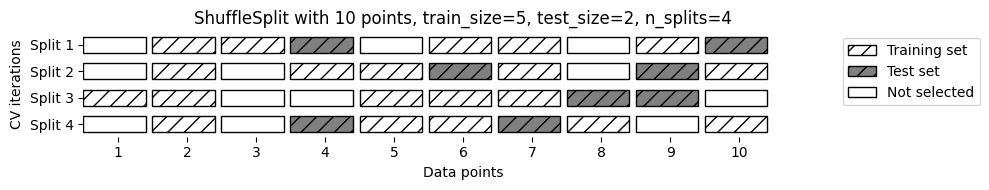

In [14]:
# ===== 书 5.1.3 节第 3 小节：画出打乱划分 =====
mglearn.plots.plot_shuffle_split()

In [15]:
# ===== 书 5.1.3 节第 3 小节：ShuffleSplit =====
from sklearn.model_selection import ShuffleSplit
shuffle_split = ShuffleSplit(test_size=.5, train_size=.5, n_splits=10)
scores = cross_val_score(logreg, iris.data, iris.target, cv=shuffle_split)
print("Cross-validation scores:\n{}".format(scores))

Cross-validation scores:
[0.96       0.94666667 0.96       0.97333333 0.96       0.94666667
 0.94666667 0.94666667 0.96       0.93333333]


In [16]:
# ===== 书 5.1.3 节第 4 小节：GroupKFold 分组交叉验证 =====
from sklearn.model_selection import GroupKFold
# 创建模拟数据集
X, y = make_blobs(n_samples=12, random_state=0)
# 假设前3个样本属于同一组，接下来的4个属于同一组，以此类推
groups = [0, 0, 0, 1, 1, 1, 1, 2, 2, 3, 3, 3]
scores = cross_val_score(logreg, X, y, groups=groups, cv=GroupKFold(n_splits=3))  # 版本适配：原书按位置传 groups，sklearn 1.x 起 groups 为关键字参数
print("Cross-validation scores:\n{}".format(scores))

Cross-validation scores:
[0.75       0.6        0.66666667]


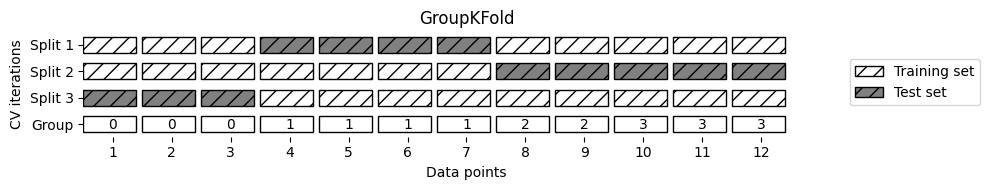

In [17]:
# ===== 书 5.1.3 节第 4 小节：画出 GroupKFold 的划分 =====
mglearn.plots.plot_group_kfold()

## 5.2 网格搜索

现在你知道了如何评估模型的泛化能力，接下来通过**调参**提升它。第 2、3 章讨论过 scikit-learn 中许多算法的参数设置——在尝试调参之前，重要的是**理解参数的含义**。找到能提供最佳泛化性能的参数取值是一项棘手的任务，但对几乎所有模型和数据集来说都是必要的。这项任务如此常见，scikit-learn 提供了标准方法帮你完成。最常用的就是**网格搜索（grid search）**：尝试你关心的参数的**所有可能组合**。

### 5.2.1 简单网格搜索

可以用两个 for 循环实现一个朴素网格搜索：对每种参数组合分别训练并评估一个分类器。

In [18]:
# ===== 书 5.2.1 节：简单的网格搜索实现 =====
from sklearn.svm import SVC
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, random_state=0)
print("Size of training set: {}   size of test set: {}".format(
      X_train.shape[0], X_test.shape[0]))

best_score = 0

for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        # 对每种参数组合都训练一个SVC
        svm = SVC(gamma=gamma, C=C)
        svm.fit(X_train, y_train)
        # 在测试集上评估SVC
        score = svm.score(X_test, y_test)
        # 如果我们得到了更高的分数，则保存该分数和对应的参数
        if score > best_score:
            best_score = score
            best_parameters = {'C': C, 'gamma': gamma}

print("Best score: {:.2f}".format(best_score))
print("Best parameters: {}".format(best_parameters))

Size of training set: 112   size of test set: 38
Best score: 0.97
Best parameters: {'C': 100, 'gamma': 0.001}


### 5.2.2 参数过拟合的风险与验证集

看到这个结果，你可能忍不住要报告"我们找到了一个精度达 97% 的模型"。然而这种说法**可能过于乐观（或者就是错的）**，原因如下：我们尝试了许多不同的参数，并选择了**在测试集上精度最高的那个**，但这个精度不一定能推广到新数据上。由于我们使用测试数据进行调参，就**不能再用它来评估模型的好坏**了——最开始把数据划分为训练集和测试集也是因为这个原因。我们需要一个独立的数据集来评估：一个在创建模型时**没有用到**的数据集。

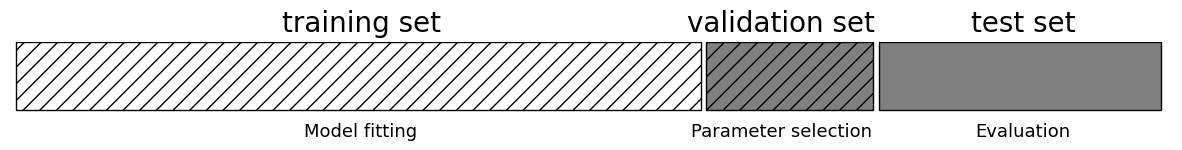

In [19]:
# ===== 书 5.2.2 节：画出训练/验证/测试三分 =====
mglearn.plots.plot_threefold_split()

In [20]:
# ===== 书 5.2.2 节：训练/验证/测试三分 + 网格搜索 =====
from sklearn.svm import SVC
# 将数据划分为 训练+验证集 与 测试集
X_trainval, X_test, y_trainval, y_test = train_test_split(
    iris.data, iris.target, random_state=0)
# 将 训练+验证集 划分为 训练集 与 验证集
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, random_state=1)
print("Size of training set: {}   size of validation set: {}   size of test set:"
      " {}\n".format(X_train.shape[0], X_valid.shape[0], X_test.shape[0]))

best_score = 0

for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        # 对每种参数组合都训练一个SVC
        svm = SVC(gamma=gamma, C=C)
        svm.fit(X_train, y_train)
        # 在验证集上评估SVC
        score = svm.score(X_valid, y_valid)
        # 如果我们得到了更高的分数，则保存该分数和对应的参数
        if score > best_score:
            best_score = score
            best_parameters = {'C': C, 'gamma': gamma}

# 在训练+验证集上重新构建一个模型，并在测试集上进行评估
svm = SVC(**best_parameters)
svm.fit(X_trainval, y_trainval)
test_score = svm.score(X_test, y_test)
print("Best score on validation set: {:.2f}".format(best_score))
print("Best parameters: ", best_parameters)
print("Test set score with best parameters: {:.2f}".format(test_score))

Size of training set: 84   size of validation set: 28   size of test set: 38

Best score on validation set: 0.96
Best parameters:  {'C': 10, 'gamma': 0.001}
Test set score with best parameters: 0.92


### 5.2.3 带交叉验证的网格搜索

虽然"训练/验证/测试"三分可行也相对常用，但这种方法**对数据的划分方式相当敏感**——对比 5.2.1 与 5.2.2 的输出：单次划分的网格搜索选了 `'C': 100, 'gamma': 0.001`，三分法的网格搜索选了 `'C': 10, 'gamma': 0.001`。为了得到对泛化性能的更好估计，可以用**交叉验证**来评估每种参数组合的性能，而不是仅做一次训练/验证划分：

In [21]:
# ===== 书 5.2.3 节：带交叉验证的朴素网格搜索 =====
# best_score 与 best_parameters 沿用 5.2.2 节代码中的定义
for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        # 对于每种参数组合都训练一个SVC
        svm = SVC(gamma=gamma, C=C)
        # 执行交叉验证
        scores = cross_val_score(svm, X_trainval, y_trainval, cv=5)
        # 计算交叉验证平均精度
        score = np.mean(scores)
        # 如果我们得到了更高的分数，则保存该分数和对应的参数
        if score > best_score:
            best_score = score
            best_parameters = {'C': C, 'gamma': gamma}

# 在训练+验证集上重新构建一个模型
svm = SVC(**best_parameters)
svm.fit(X_trainval, y_trainval)

,C,10
,kernel,'rbf'
,degree,3
,gamma,0.1
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


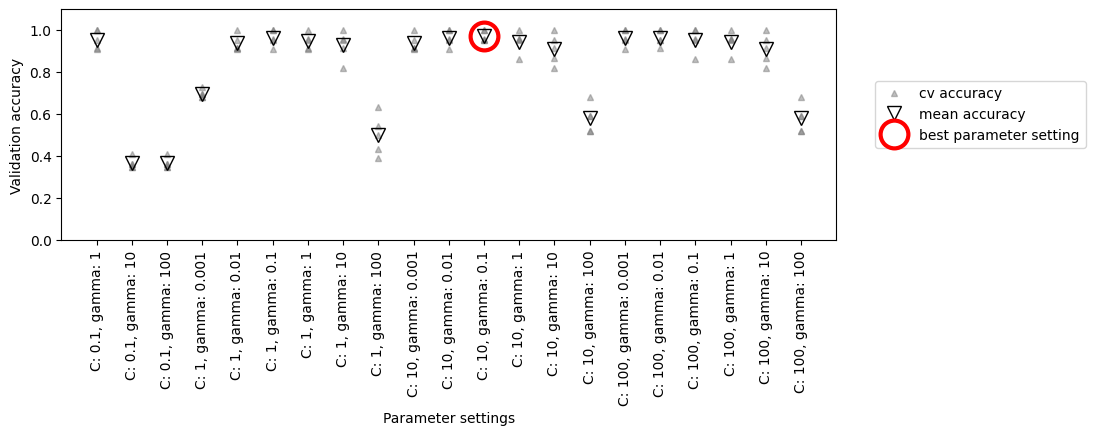

In [22]:
# ===== 书 5.2.3 节：画出带交叉验证的网格搜索 =====
mglearn.plots.plot_cross_val_selection()

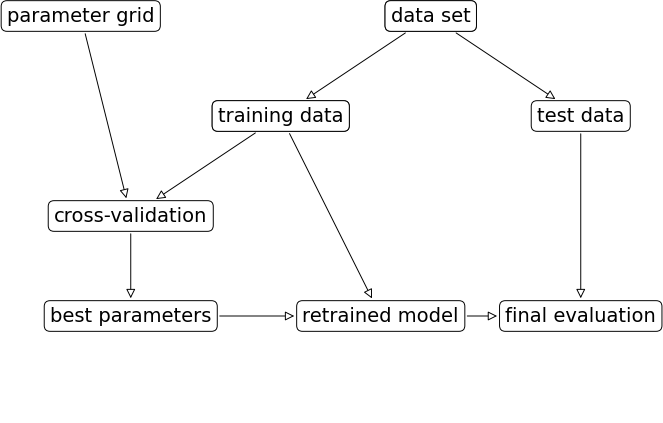

In [23]:
# ===== 书 5.2.3 节：GridSearchCV 全流程总览 =====
mglearn.plots.plot_grid_search_overview()

In [24]:
# ===== 书 5.2.3 节：用字典定义参数网格 =====
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100],
              'gamma': [0.001, 0.01, 0.1, 1, 10, 100]}
print("Parameter grid:\n{}".format(param_grid))

Parameter grid:
{'C': [0.001, 0.01, 0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1, 10, 100]}


In [25]:
# ===== 书 5.2.3 节：实例化 GridSearchCV =====
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
grid_search = GridSearchCV(SVC(), param_grid, cv=5)

In [26]:
# ===== 书 5.2.3 节：外层仍要留出测试集 =====
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, random_state=0)

In [27]:
# ===== 书 5.2.3 节：fit 一行，180 个模型 =====
grid_search.fit(X_train, y_train)

,estimator,SVC()
,param_grid,"{'C': [0.001, 0.01, ...], 'gamma': [0.001, 0.01, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


In [28]:
# ===== 书 5.2.3 节：测试集评估 =====
print("Test set score: {:.2f}".format(grid_search.score(X_test, y_test)))

Test set score: 0.97


In [29]:
# ===== 书 5.2.3 节：最佳参数与最佳交叉验证分数 =====
print("Best parameters: {}".format(grid_search.best_params_))
print("Best cross-validation score: {:.2f}".format(grid_search.best_score_))

Best parameters: {'C': 10, 'gamma': 0.1}
Best cross-validation score: 0.97


In [30]:
# ===== 书 5.2.3 节：取出最佳模型 =====
print("Best estimator:\n{}".format(grid_search.best_estimator_))

Best estimator:
SVC(C=10, gamma=0.1)


In [31]:
# ===== 书 5.2.3 节第 1 小节：cv_results_ 转 DataFrame =====
import pandas as pd
# 转换为DataFrame（数据框）
results = pd.DataFrame(grid_search.cv_results_)
# 显示前5行（display 是 Jupyter 的富文本展示函数）
display(results.head())

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_gamma,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.000904,4.922504e-04,0.000600,0.000490,0.001,0.001,"{'C': 0.001, 'gamma': 0.001}",0.347826,0.347826,0.363636,0.363636,0.409091,0.366403,0.022485,22
1,0.000801,4.006672e-04,0.000399,0.000489,0.001,0.010,"{'C': 0.001, 'gamma': 0.01}",0.347826,0.347826,0.363636,0.363636,0.409091,0.366403,0.022485,22
2,0.000800,4.000924e-04,0.000600,0.000490,0.001,0.100,"{'C': 0.001, 'gamma': 0.1}",0.347826,0.347826,0.363636,0.363636,0.409091,0.366403,0.022485,22
3,0.000601,4.907700e-04,0.000702,0.000602,0.001,1.000,"{'C': 0.001, 'gamma': 1}",0.347826,0.347826,0.363636,0.363636,0.409091,0.366403,0.022485,22
4,0.001000,6.289914e-07,0.000600,0.000490,0.001,10.000,"{'C': 0.001, 'gamma': 10}",0.347826,0.347826,0.363636,0.363636,0.409091,0.366403,0.022485,22


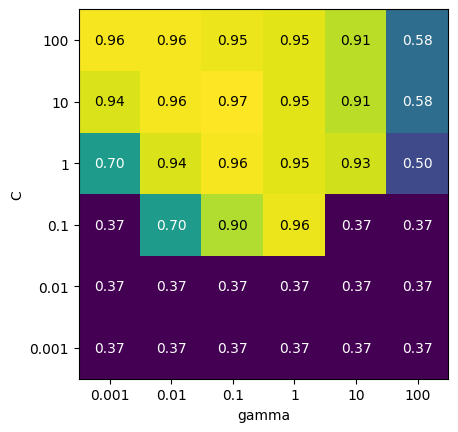

In [32]:
# ===== 书 5.2.3 节第 1 小节：参数热图 =====
scores = np.array(results.mean_test_score).reshape(6, 6)

# 对交叉验证平均分数作图
mglearn.tools.heatmap(scores, xlabel='gamma', xticklabels=param_grid['gamma'],
                      ylabel='C', yticklabels=param_grid['C'], cmap="viridis")

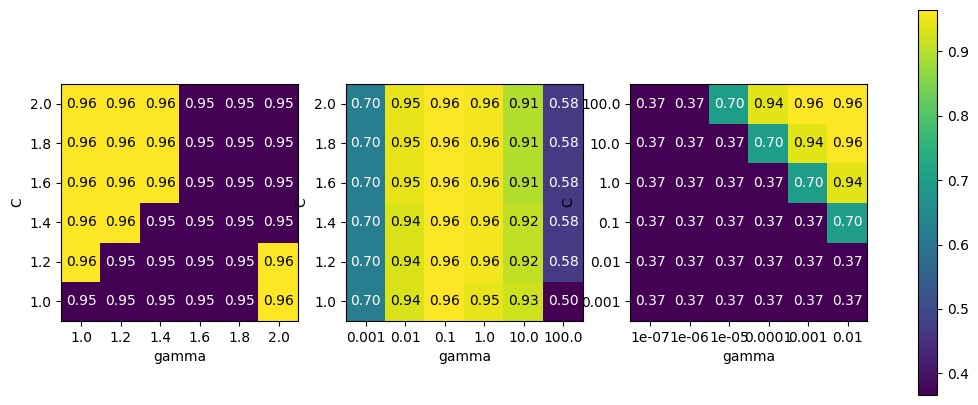

In [33]:
# ===== 书 5.2.3 节第 1 小节：三种坏网格 =====
fig, axes = plt.subplots(1, 3, figsize=(13, 5))

param_grid_linear = {'C': np.linspace(1, 2, 6),
                     'gamma':  np.linspace(1, 2, 6)}

param_grid_one_log = {'C': np.linspace(1, 2, 6),
                      'gamma':  np.logspace(-3, 2, 6)}

param_grid_range = {'C': np.logspace(-3, 2, 6),
                    'gamma':  np.logspace(-7, -2, 6)}

for param_grid, ax in zip([param_grid_linear, param_grid_one_log,
                           param_grid_range], axes):
    grid_search = GridSearchCV(SVC(), param_grid, cv=5)
    grid_search.fit(X_train, y_train)
    scores = grid_search.cv_results_['mean_test_score'].reshape(6, 6)

    # 对交叉验证平均分数作图
    scores_image = mglearn.tools.heatmap(
        scores, xlabel='gamma', ylabel='C', xticklabels=param_grid['gamma'],
        yticklabels=param_grid['C'], cmap="viridis", ax=ax)

plt.colorbar(scores_image, ax=axes.tolist())

In [34]:
# ===== 书 5.2.3 节第 2 小节：条件参数用字典列表 =====
param_grid = [{'kernel': ['rbf'],
               'C': [0.001, 0.01, 0.1, 1, 10, 100],
               'gamma': [0.001, 0.01, 0.1, 1, 10, 100]},
              {'kernel': ['linear'],
               'C': [0.001, 0.01, 0.1, 1, 10, 100]}]
print("List of grids:\n{}".format(param_grid))

List of grids:
[{'kernel': ['rbf'], 'C': [0.001, 0.01, 0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1, 10, 100]}, {'kernel': ['linear'], 'C': [0.001, 0.01, 0.1, 1, 10, 100]}]


In [35]:
# ===== 书 5.2.3 节第 2 小节：对字典列表运行网格搜索 =====
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)
print("Best parameters: {}".format(grid_search.best_params_))
print("Best cross-validation score: {:.2f}".format(grid_search.best_score_))

Best parameters: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Best cross-validation score: 0.97


In [36]:
# ===== 书 5.2.3 节第 3 小节（1）：嵌套交叉验证一行版 =====
scores = cross_val_score(GridSearchCV(SVC(), param_grid, cv=5),
                         iris.data, iris.target, cv=5)
print("Cross-validation scores: ", scores)
print("Mean cross-validation score: ", scores.mean())

Cross-validation scores:  [0.96666667 1.         0.9        0.96666667 1.        ]
Mean cross-validation score:  0.9666666666666668


In [37]:
# ===== 书 5.2.3 节第 3 小节（1）：嵌套交叉验证展开版 =====
def nested_cv(X, y, inner_cv, outer_cv, Classifier, parameter_grid):
    outer_scores = []
    # 对于外层交叉验证的每次数据划分，split方法返回索引值
    for training_samples, test_samples in outer_cv.split(X, y):
        # 利用内层交叉验证找到最佳参数
        best_params = {}   # 原书此处误写为 best_parms（该变量从未被使用，不影响运行）
        best_score = -np.inf
        # 遍历参数
        for parameters in parameter_grid:
            # 在内层划分中累加分数
            cv_scores = []
            # 遍历内层交叉验证
            for inner_train, inner_test in inner_cv.split(
                    X[training_samples], y[training_samples]):
                # 对于给定的参数和训练数据来构建分类器
                clf = Classifier(**parameters)
                clf.fit(X[inner_train], y[inner_train])
                # 在内层测试集上进行评估
                score = clf.score(X[inner_test], y[inner_test])
                cv_scores.append(score)
            # 计算内层交叉验证的平均分数
            mean_score = np.mean(cv_scores)
            if mean_score > best_score:
                # 如果比前面的模型都要好，则保存其参数
                best_score = mean_score
                best_params = parameters
        # 利用外层训练集和最佳参数来构建模型
        clf = Classifier(**best_params)
        clf.fit(X[training_samples], y[training_samples])
        # 评估模型
        outer_scores.append(clf.score(X[test_samples], y[test_samples]))
    return np.array(outer_scores)

In [38]:
# ===== 书 5.2.3 节第 3 小节（1）：运行展开版 =====
from sklearn.model_selection import ParameterGrid, StratifiedKFold
scores = nested_cv(iris.data, iris.target, StratifiedKFold(5),
          StratifiedKFold(5), SVC, ParameterGrid(param_grid))
print("Cross-validation scores: {}".format(scores))

Cross-validation scores: [0.96666667 1.         0.96666667 0.96666667 1.        ]


## 5.3 评估指标与评分

到目前为止，我们用**精度**（正确分类的样本所占的比例）评估分类性能，用 \(R^2\) 评估回归性能。但总结监督模型在给定数据集上的表现有多种方法，这两个只是其中两种。实践中它们可能不适用于你的应用——**在选择模型与调参时，选择正确的指标很重要**。

### 5.3.1 牢记最终目标

选择指标时应始终牢记机器学习应用的**最终目标**。实践中我们通常不仅关心精确的预测，还要把预测结果用于更大的决策过程。在选择机器学习指标之前，应考虑应用的高级目标，这通常被称为**商业指标（business metric）**；对一个机器学习应用选择特定算法的结果被称为**商业影响（business impact）**（译注：作者在脚注里请有科学头脑的读者原谅这一节的商业语言——"不忘最终目标"在科学中同样重要，只是他想不出与"商业影响"含义相同的科学词汇）。高级目标可能是避免交通事故、减少入院人数，也可能是吸引更多网站用户、让用户花更多钱。选择模型或调参时，应选择**对商业指标具有最大正面影响**的模型或参数值。

### 5.3.2 二分类指标

二分类可能是实践中最常见的机器学习应用，也是概念最简单的应用——但即使评估这个简单任务也有注意事项。在深入研究替代指标之前，先看精度会如何误导我们。对于二分类问题，我们通常说**正类（positive class）**和**反类（negative class）**，而正类是**我们要寻找的类**。

In [39]:
# ===== 书 5.3.2 节第 2 小节：构造"9 与其他"的不平衡数据集 =====
from sklearn.datasets import load_digits

digits = load_digits()
y = digits.target == 9

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, y, random_state=0)

In [40]:
# ===== 书 5.3.2 节第 2 小节：总是预测多数类 =====
from sklearn.dummy import DummyClassifier
dummy_majority = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred_most_frequent = dummy_majority.predict(X_test)
print("Unique predicted labels: {}".format(np.unique(pred_most_frequent)))
print("Test score: {:.2f}".format(dummy_majority.score(X_test, y_test)))

Unique predicted labels: [False]
Test score: 0.90


In [41]:
# ===== 书 5.3.2 节第 2 小节：深度为 2 的决策树 =====
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
pred_tree = tree.predict(X_test)
print("Test score: {:.2f}".format(tree.score(X_test, y_test)))

Test score: 0.92


In [42]:
# ===== 书 5.3.2 节第 2 小节：随机 dummy 与 LogisticRegression =====
from sklearn.linear_model import LogisticRegression

dummy = DummyClassifier().fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
print("dummy score: {:.2f}".format(dummy.score(X_test, y_test)))

logreg = LogisticRegression(C=0.1).fit(X_train, y_train)
pred_logreg = logreg.predict(X_test)
print("logreg score: {:.2f}".format(logreg.score(X_test, y_test)))

dummy score: 0.90
logreg score: 0.98


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [43]:
# ===== 书 5.3.2 节第 3 小节：混淆矩阵 =====
from sklearn.metrics import confusion_matrix

confusion = confusion_matrix(y_test, pred_logreg)
print("Confusion matrix:\n{}".format(confusion))

Confusion matrix:
[[402   1]
 [  6  41]]


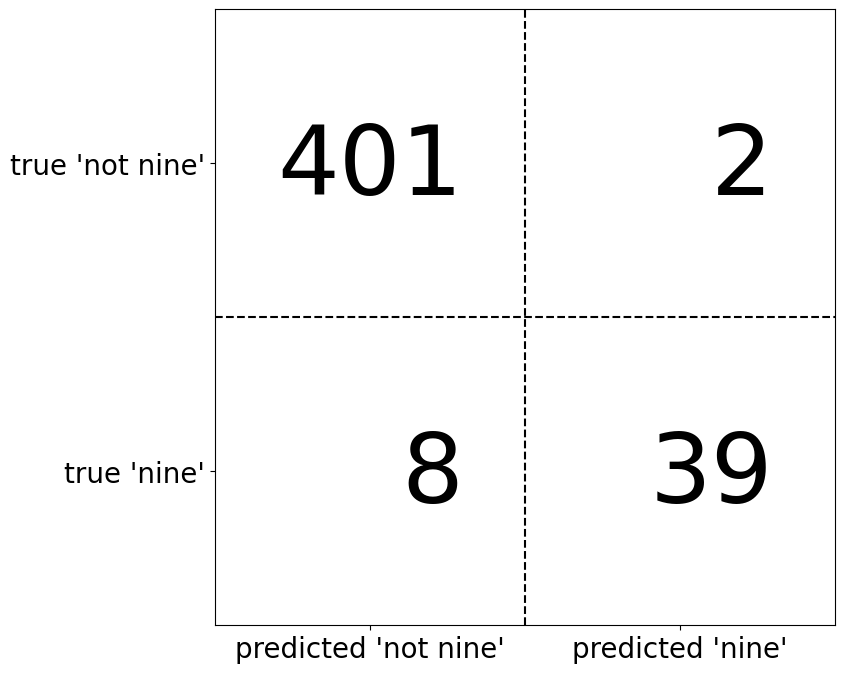

In [44]:
# ===== 书 5.3.2 节第 3 小节：混淆矩阵图示 =====
mglearn.plots.plot_confusion_matrix_illustration()

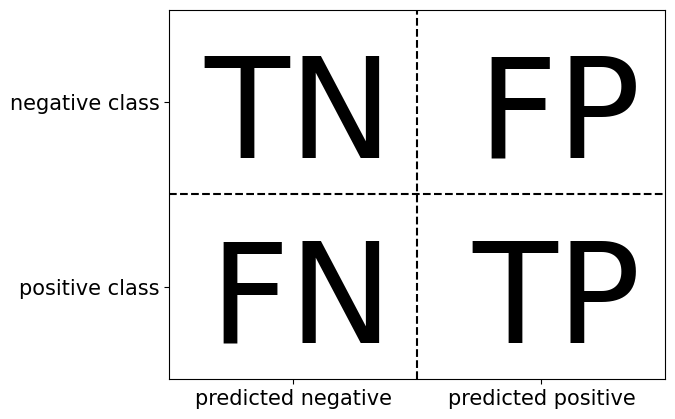

In [45]:
# ===== 书 5.3.2 节第 3 小节：抽象的 2×2 记法 =====
mglearn.plots.plot_binary_confusion_matrix()

In [46]:
# ===== 书 5.3.2 节第 3 小节：四个模型的混淆矩阵对比 =====
print("Most frequent class:")
print(confusion_matrix(y_test, pred_most_frequent))
print("\nDummy model:")
print(confusion_matrix(y_test, pred_dummy))
print("\nDecision tree:")
print(confusion_matrix(y_test, pred_tree))
print("\nLogistic Regression")
print(confusion_matrix(y_test, pred_logreg))

Most frequent class:
[[403   0]
 [ 47   0]]

Dummy model:
[[403   0]
 [ 47   0]]

Decision tree:
[[390  13]
 [ 24  23]]

Logistic Regression
[[402   1]
 [  6  41]]


In [47]:
# ===== 书 5.3.2 节第 3 小节：四个模型的 f1 分数 =====
from sklearn.metrics import f1_score
print("f1 score most frequent: {:.2f}".format(
        f1_score(y_test, pred_most_frequent)))
print("f1 score dummy: {:.2f}".format(f1_score(y_test, pred_dummy)))
print("f1 score tree: {:.2f}".format(f1_score(y_test, pred_tree)))
print("f1 score logistic regression: {:.2f}".format(
        f1_score(y_test, pred_logreg)))

f1 score most frequent: 0.00


f1 score dummy: 0.00
f1 score tree: 0.55
f1 score logistic regression: 0.92


In [48]:
# ===== 书 5.3.2 节第 3 小节：most_frequent 的分类报告 =====
from sklearn.metrics import classification_report
print(classification_report(y_test, pred_most_frequent,
                            target_names=["not nine", "nine"]))

              precision    recall  f1-score   support

    not nine       0.90      1.00      0.94       403
        nine       0.00      0.00      0.00        47

    accuracy                           0.90       450
   macro avg       0.45      0.50      0.47       450
weighted avg       0.80      0.90      0.85       450



C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [49]:
# ===== 书 5.3.2 节第 3 小节：dummy 的分类报告 =====
print(classification_report(y_test, pred_dummy,
                            target_names=["not nine", "nine"]))

              precision    recall  f1-score   support

    not nine       0.90      1.00      0.94       403
        nine       0.00      0.00      0.00        47

    accuracy                           0.90       450
   macro avg       0.45      0.50      0.47       450
weighted avg       0.80      0.90      0.85       450



C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [50]:
# ===== 书 5.3.2 节第 3 小节：logreg 的分类报告 =====
print(classification_report(y_test, pred_logreg,
                            target_names=["not nine", "nine"]))

              precision    recall  f1-score   support

    not nine       0.99      1.00      0.99       403
        nine       0.98      0.87      0.92        47

    accuracy                           0.98       450
   macro avg       0.98      0.93      0.96       450
weighted avg       0.98      0.98      0.98       450



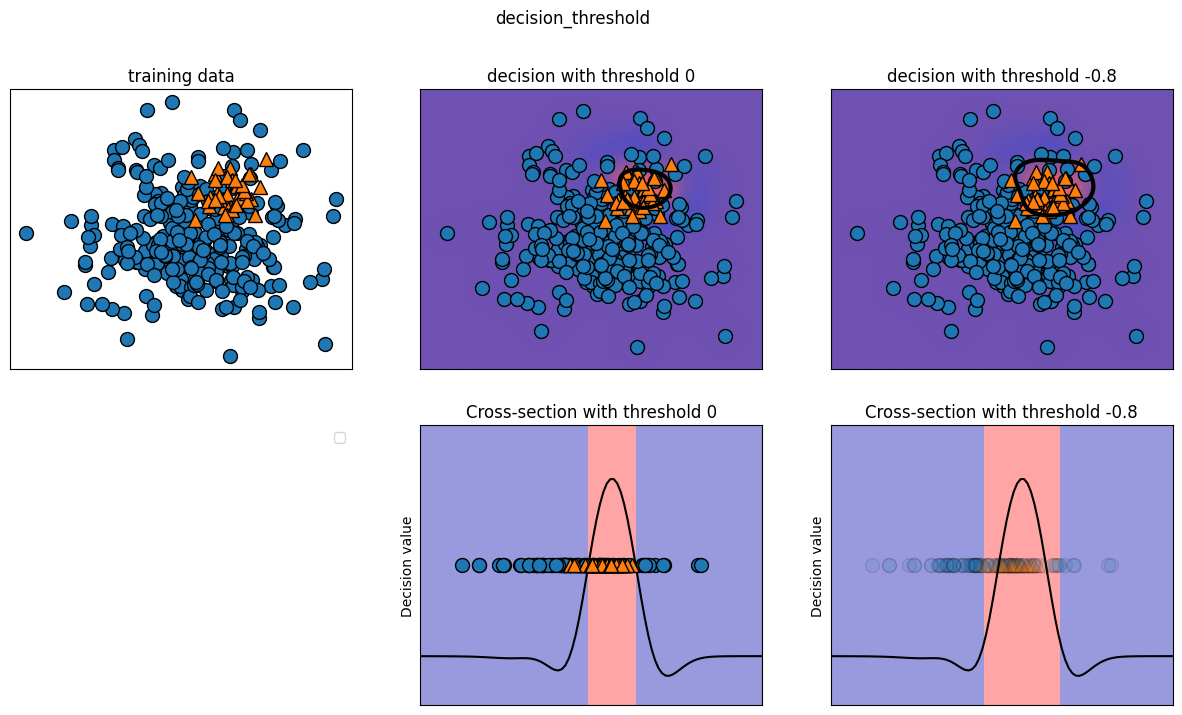

In [51]:
# ===== 书 5.3.2 节第 4 小节：不平衡 blobs + 核 SVM =====
from mglearn.datasets import make_blobs
X, y = make_blobs(n_samples=(400, 50), centers=2, cluster_std=[7.0, 2],
                  random_state=22)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
svc = SVC(gamma=.05).fit(X_train, y_train)
mglearn.plots.plot_decision_threshold()

In [52]:
# ===== 书 5.3.2 节第 4 小节：默认阈值的分类报告 =====
print(classification_report(y_test, svc.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98       102
           1       0.73      1.00      0.85        11

    accuracy                           0.96       113
   macro avg       0.87      0.98      0.91       113
weighted avg       0.97      0.96      0.97       113



In [53]:
# ===== 书 5.3.2 节第 4 小节：把阈值降到 -0.8 =====
y_pred_lower_threshold = svc.decision_function(X_test) > -.8

In [54]:
# ===== 书 5.3.2 节第 4 小节：低阈值的分类报告 =====
print(classification_report(y_test, y_pred_lower_threshold))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97       102
           1       0.65      1.00      0.79        11

    accuracy                           0.95       113
   macro avg       0.82      0.97      0.88       113
weighted avg       0.97      0.95      0.95       113



In [55]:
# ===== 书 5.3.2 节第 5 小节：计算 PR 曲线 =====
from sklearn.metrics import precision_recall_curve
precision, recall, thresholds = precision_recall_curve(
    y_test, svc.decision_function(X_test))

Text(0, 0.5, 'Recall')

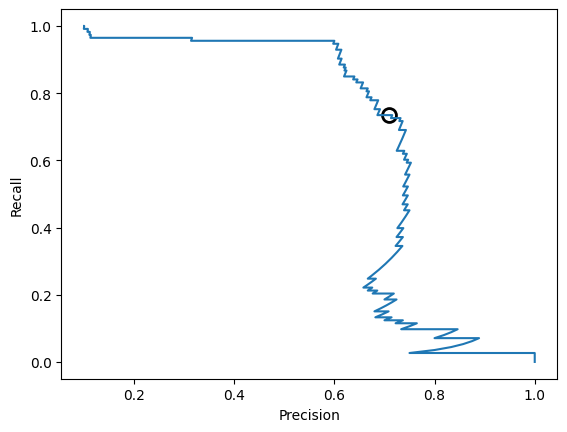

In [56]:
# ===== 书 5.3.2 节第 5 小节：绘制 PR 曲线 =====
# 使用更多数据点来得到更加平滑的曲线
X, y = make_blobs(n_samples=(4000, 500), centers=2, cluster_std=[7.0, 2],
                  random_state=22)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
svc = SVC(gamma=.05).fit(X_train, y_train)
precision, recall, thresholds = precision_recall_curve(
    y_test, svc.decision_function(X_test))
# 找到最接近于0的阈值
close_zero = np.argmin(np.abs(thresholds))
plt.plot(precision[close_zero], recall[close_zero], 'o', markersize=10,
         label="threshold zero", fillstyle="none", c='k', mew=2)

plt.plot(precision, recall, label="precision recall curve")
plt.xlabel("Precision")
plt.ylabel("Recall")

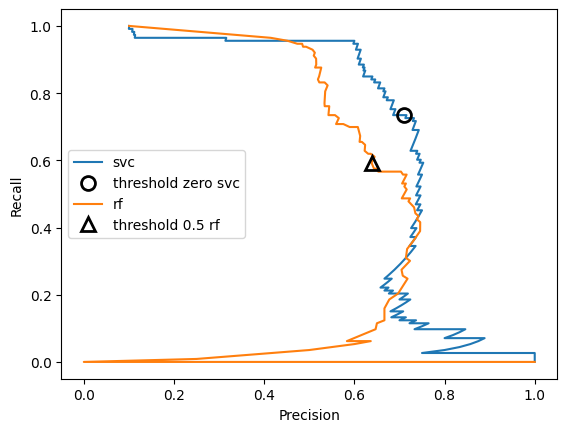

In [57]:
# ===== 书 5.3.2 节第 5 小节：SVC 与随机森林的 PR 曲线对比 =====
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=0, max_features=2)
rf.fit(X_train, y_train)

# RandomForestClassifier有predict_proba，但没有decision_function
precision_rf, recall_rf, thresholds_rf = precision_recall_curve(
    y_test, rf.predict_proba(X_test)[:, 1])

plt.plot(precision, recall, label="svc")

plt.plot(precision[close_zero], recall[close_zero], 'o', markersize=10,
         label="threshold zero svc", fillstyle="none", c='k', mew=2)

plt.plot(precision_rf, recall_rf, label="rf")

close_default_rf = np.argmin(np.abs(thresholds_rf - 0.5))
plt.plot(precision_rf[close_default_rf], recall_rf[close_default_rf], '^', c='k',
         markersize=10, label="threshold 0.5 rf", fillstyle="none", mew=2)
plt.xlabel("Precision")
plt.ylabel("Recall")
plt.legend(loc="best")

In [58]:
# ===== 书 5.3.2 节第 5 小节：只看 f1 会漏掉细节 =====
print("f1_score of random forest: {:.3f}".format(
    f1_score(y_test, rf.predict(X_test))))
print("f1_score of svc: {:.3f}".format(f1_score(y_test, svc.predict(X_test))))

f1_score of random forest: 0.611
f1_score of svc: 0.722


In [59]:
# ===== 书 5.3.2 节第 5 小节：平均准确率 AP =====
from sklearn.metrics import average_precision_score
ap_rf = average_precision_score(y_test, rf.predict_proba(X_test)[:, 1])
ap_svc = average_precision_score(y_test, svc.decision_function(X_test))
print("Average precision of random forest: {:.3f}".format(ap_rf))
print("Average precision of svc: {:.3f}".format(ap_svc))

Average precision of random forest: 0.613
Average precision of svc: 0.698


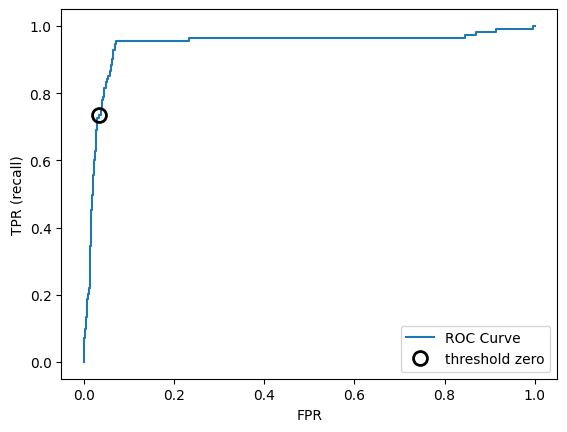

In [60]:
# ===== 书 5.3.2 节第 6 小节：SVM 的 ROC 曲线 =====
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, svc.decision_function(X_test))

plt.plot(fpr, tpr, label="ROC Curve")
plt.xlabel("FPR")
plt.ylabel("TPR (recall)")
# 找到最接近于0的阈值
close_zero = np.argmin(np.abs(thresholds))
plt.plot(fpr[close_zero], tpr[close_zero], 'o', markersize=10,
         label="threshold zero", fillstyle="none", c='k', mew=2)
plt.legend(loc=4)

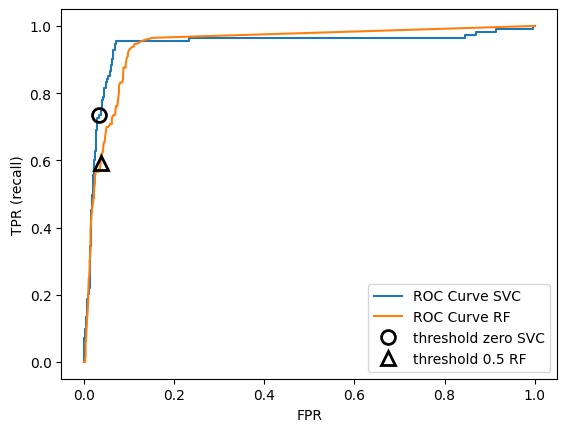

In [61]:
# ===== 书 5.3.2 节第 6 小节：SVM 与随机森林的 ROC 对比 =====
from sklearn.metrics import roc_curve
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, rf.predict_proba(X_test)[:, 1])

plt.plot(fpr, tpr, label="ROC Curve SVC")
plt.plot(fpr_rf, tpr_rf, label="ROC Curve RF")

plt.xlabel("FPR")
plt.ylabel("TPR (recall)")
plt.plot(fpr[close_zero], tpr[close_zero], 'o', markersize=10,
         label="threshold zero SVC", fillstyle="none", c='k', mew=2)
close_default_rf = np.argmin(np.abs(thresholds_rf - 0.5))
# 原书此处误写为 tpr[close_default_rf]（拿 SVC 的 TPR 数组配 RF 的阈值索引），已改为 tpr_rf
plt.plot(fpr_rf[close_default_rf], tpr_rf[close_default_rf], '^', markersize=10,
         label="threshold 0.5 RF", fillstyle="none", c='k', mew=2)

plt.legend(loc=4)

In [62]:
# ===== 书 5.3.2 节第 6 小节：计算 AUC =====
from sklearn.metrics import roc_auc_score
rf_auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])
svc_auc = roc_auc_score(y_test, svc.decision_function(X_test))
print("AUC for Random Forest: {:.3f}".format(rf_auc))
print("AUC for SVC: {:.3f}".format(svc_auc))

AUC for Random Forest: 0.944
AUC for SVC: 0.943


gamma = 1.00  accuracy = 0.90  AUC = 0.50


gamma = 0.05  accuracy = 0.90  AUC = 1.00


gamma = 0.01  accuracy = 0.90  AUC = 1.00


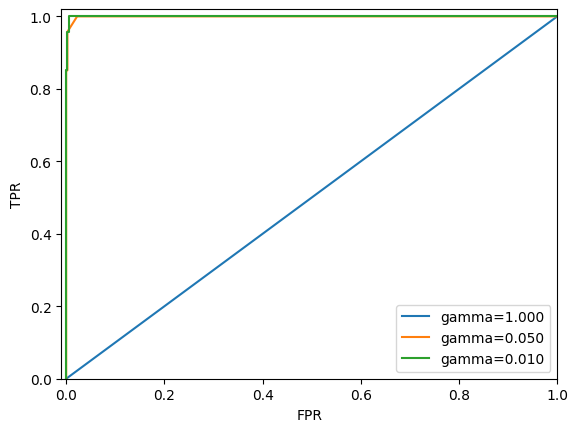

In [63]:
# ===== 书 5.3.2 节第 6 小节：不同 gamma 的精度与 AUC =====
y = digits.target == 9

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, y, random_state=0)

plt.figure()

for gamma in [1, 0.05, 0.01]:
    svc = SVC(gamma=gamma).fit(X_train, y_train)
    accuracy = svc.score(X_test, y_test)
    auc = roc_auc_score(y_test, svc.decision_function(X_test))
    fpr, tpr, _ = roc_curve(y_test, svc.decision_function(X_test))
    print("gamma = {:.2f}  accuracy = {:.2f}  AUC = {:.2f}".format(
    gamma, accuracy, auc))
    plt.plot(fpr, tpr, label="gamma={:.3f}".format(gamma))
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.xlim(-0.01, 1)
plt.ylim(0, 1.02)
plt.legend(loc="best")

### 5.3.3 多分类指标

多分类的所有指标基本上都来自二分类指标，但要对**所有类别进行平均**。多分类的精度定义为正确分类的样本所占的比例；类别不平衡时精度同样不是好度量——想象一个三分类问题，85% 属于类别 A、10% 属于 B、5% 属于 C，在这上面 85% 的精度说明了什么？一般来说，**多分类结果比二分类结果更难理解**。除了精度，常用工具有混淆矩阵和分类报告（二分类的例子中都见过）。把它们应用到 digits 数据集 10 种手写数字的分类任务：

In [64]:
# ===== 书 5.3.3 节：digits 十分类的精度与混淆矩阵 =====
from sklearn.metrics import accuracy_score
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, random_state=0)
lr = LogisticRegression().fit(X_train, y_train)
pred = lr.predict(X_test)
print("Accuracy: {:.3f}".format(accuracy_score(y_test, pred)))
print("Confusion matrix:\n{}".format(confusion_matrix(y_test, pred)))

Accuracy: 0.951
Confusion matrix:
[[37  0  0  0  0  0  0  0  0  0]
 [ 0 40  0  0  0  0  0  0  2  1]
 [ 0  1 40  3  0  0  0  0  0  0]
 [ 0  0  0 43  0  0  0  0  1  1]
 [ 0  0  0  0 37  0  0  1  0  0]
 [ 0  0  0  0  0 46  0  0  0  2]
 [ 0  1  0  0  0  0 51  0  0  0]
 [ 0  0  0  1  1  0  0 46  0  0]
 [ 0  3  1  0  0  0  0  0 43  1]
 [ 0  0  0  0  0  1  0  0  1 45]]


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


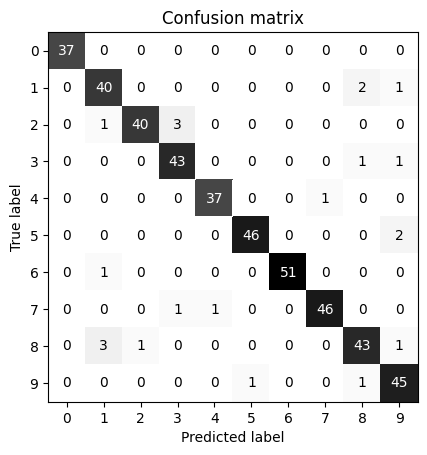

In [65]:
# ===== 书 5.3.3 节：混淆矩阵热图 =====
scores_image = mglearn.tools.heatmap(
    confusion_matrix(y_test, pred), xlabel='Predicted label',
    ylabel='True label', xticklabels=digits.target_names,
    yticklabels=digits.target_names, cmap=plt.cm.gray_r, fmt="%d")
plt.title("Confusion matrix")
plt.gca().invert_yaxis()

In [66]:
# ===== 书 5.3.3 节：十分类的 classification_report =====
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       0.89      0.93      0.91        43
           2       0.98      0.91      0.94        44
           3       0.91      0.96      0.93        45
           4       0.97      0.97      0.97        38
           5       0.98      0.96      0.97        48
           6       1.00      0.98      0.99        52
           7       0.98      0.96      0.97        48
           8       0.91      0.90      0.91        48
           9       0.90      0.96      0.93        47

    accuracy                           0.95       450
   macro avg       0.95      0.95      0.95       450
weighted avg       0.95      0.95      0.95       450



In [67]:
# ===== 书 5.3.3 节：micro 与 macro 平均 =====
print("Micro average f1 score: {:.3f}".format
       (f1_score(y_test, pred, average="micro")))
print("Macro average f1 score: {:.3f}".format
       (f1_score(y_test, pred, average="macro")))

Micro average f1 score: 0.951
Macro average f1 score: 0.952


### 5.3.4 回归指标

对回归问题可以像分类问题一样详细评估，例如对比分析"目标值估计过高"与"估计过低"。但对我们见过的大多数应用来说，**使用默认 \(R^2\) 就足够了**——它由所有回归器的 score 方法给出。业务决策有时是根据**均方误差（MSE）**或**平均绝对误差（MAE）**做出的，这可能会鼓励人们用这些指标来调参。但一般来说，\(R^2\) 是评估回归模型更直观的指标。

### 5.3.5 在模型选择中使用评估指标

前面详细讨论了许多评估方法。但我们通常希望在使用 **GridSearchCV 或 cross_val_score** 做模型选择时，能使用 AUC 等指标。scikit-learn 提供了非常简单的实现：**scoring 参数**，可同时用于 GridSearchCV 和 cross_val_score——只需提供一个字符串，描述想使用的评估指标。例如想在 digits"9 与其他"任务上用 AUC 评估 SVM：把分数从默认值（精度）改成 AUC，传 `"roc_auc"` 作为 scoring 参数的值：

In [68]:
# ===== 书 5.3.5 节：cross_val_score 的 scoring 参数 =====
# 分类问题的默认评分是精度
print("Default scoring: {}".format(
    cross_val_score(SVC(), digits.data, digits.target == 9)))
# 指定 scoring="accuracy" 不会改变结果
explicit_accuracy =  cross_val_score(SVC(), digits.data, digits.target == 9,
                                     scoring="accuracy")
print("Explicit accuracy scoring: {}".format(explicit_accuracy))
roc_auc =  cross_val_score(SVC(), digits.data, digits.target == 9,
                           scoring="roc_auc")
print("AUC scoring: {}".format(roc_auc))

Default scoring: [0.975      0.99166667 1.         0.99442897 0.98050139]
Explicit accuracy scoring: [0.975      0.99166667 1.         0.99442897 0.98050139]


AUC scoring: [0.99717078 0.99854252 1.         0.999828   0.98400413]


In [69]:
# ===== 书 5.3.5 节：用精度做网格搜索（刻意用了不太好的网格） =====
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target == 9, random_state=0)

# 我们给出了不太好的网格来说明：
param_grid = {'gamma': [0.0001, 0.01, 0.1, 1, 10]}
# 使用默认的精度：
grid = GridSearchCV(SVC(), param_grid=param_grid)
grid.fit(X_train, y_train)
print("Grid-Search with accuracy")
print("Best parameters:", grid.best_params_)
print("Best cross-validation score (accuracy): {:.3f}".format(grid.best_score_))
print("Test set AUC: {:.3f}".format(
    roc_auc_score(y_test, grid.decision_function(X_test))))
print("Test set accuracy: {:.3f}".format(grid.score(X_test, y_test)))

Grid-Search with accuracy
Best parameters: {'gamma': 0.0001}
Best cross-validation score (accuracy): 0.976
Test set AUC: 0.992
Test set accuracy: 0.973


In [70]:
# ===== 书 5.3.5 节：换用 AUC 评分 =====
# 使用AUC评分来代替：
grid = GridSearchCV(SVC(), param_grid=param_grid, scoring="roc_auc")
grid.fit(X_train, y_train)
print("\nGrid-Search with AUC")
print("Best parameters:", grid.best_params_)
print("Best cross-validation score (AUC): {:.3f}".format(grid.best_score_))
print("Test set AUC: {:.3f}".format(
    roc_auc_score(y_test, grid.decision_function(X_test))))
print("Test set accuracy: {:.3f}".format(grid.score(X_test, y_test)))


Grid-Search with AUC
Best parameters: {'gamma': 0.01}
Best cross-validation score (AUC): 0.998
Test set AUC: 1.000
Test set accuracy: 1.000


In [71]:
# ===== 书 5.3.5 节：查看所有可用的 scorer =====
from sklearn.metrics import get_scorer_names  # 版本适配：SCORERS 已移除，改用 get_scorer_names()
# 版本适配：改用 get_scorer_names()
from sklearn.metrics import get_scorer_names
print("Available scorers:\n{}".format(sorted(get_scorer_names())))

Available scorers:
['accuracy', 'adjusted_mutual_info_score', 'adjusted_rand_score', 'average_precision', 'balanced_accuracy', 'completeness_score', 'd2_absolute_error_score', 'explained_variance', 'f1', 'f1_macro', 'f1_micro', 'f1_samples', 'f1_weighted', 'fowlkes_mallows_score', 'homogeneity_score', 'jaccard', 'jaccard_macro', 'jaccard_micro', 'jaccard_samples', 'jaccard_weighted', 'matthews_corrcoef', 'mutual_info_score', 'neg_brier_score', 'neg_log_loss', 'neg_max_error', 'neg_mean_absolute_error', 'neg_mean_absolute_percentage_error', 'neg_mean_gamma_deviance', 'neg_mean_poisson_deviance', 'neg_mean_squared_error', 'neg_mean_squared_log_error', 'neg_median_absolute_error', 'neg_negative_likelihood_ratio', 'neg_root_mean_squared_error', 'neg_root_mean_squared_log_error', 'normalized_mutual_info_score', 'positive_likelihood_ratio', 'precision', 'precision_macro', 'precision_micro', 'precision_samples', 'precision_weighted', 'r2', 'rand_score', 'recall', 'recall_macro', 'recall_micro

## 5.4 小结与展望

本章讨论了交叉验证、网格搜索和评估指标，它们是**评估与改进机器学习算法的基础**。本章介绍的工具加上第 2、3 章介绍的算法，是每位机器学习从业者赖以生存的工具。